# Day10：记住自己的线索，再学会把信息交给队友

RedMoon 的互动学习练习。代码骨架与注释由教师提供，供阅读、修改和复跑。
每局两个独立均匀私有提示 a/b：发送者只见 a，接收者只见 b。
接收者最后选门：提示相同选左 0，不同选右 1；正确得共同奖励 1，否则 0。

t=0 看自己的提示；t=1 发送者发消息；t=2 接收者看消息；
t=3 消息消失，接收者选门，本局真正终止。其他阶段只能等待。
本练习用两个 GRU、普通离散消息和 REINFORCE；没有给消息规定正确标签，
也没有训练 Q Critic、COMA 或 PPO。前面的反事实 Q 表仍是独立教学算例。

## 1. 配置：先认清数量和评分

| 变量 | 含义 |
|---|---|
| `episodes_per_batch` | 每批同时完成多少个独立共同回合，记为 B |
| `num_updates` | 每批重新采样并更新一次，共重复多少批 |
| `horizon` | 每局四条真实环境转移，记为 T |
| `hidden_size` | 每个人自己的记忆向量长度 H |
| `baseline` | 固定参照 0.5；评分为最终奖励减参照 |
| `entropy_coef` | 鼓励保留探索的权重，不提供消息含义 |

gamma=1，前三步奖励为 0，两次自由决策的完整回报都等于最终奖励。
初始网络正常随机初始化；不手填编码、解码或正确动作权重。

In [1]:
import os
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import itertools
import json
import math
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

torch.set_num_threads(1)
seed, horizon, hidden_size = 7, 4, 24
episodes_per_batch, num_updates = 256, 800
learning_rate, baseline, entropy_coef = 0.005, 0.5, 0.01
max_grad_norm, eval_episodes = 1.0, 1000
LEFT, RIGHT, WAIT = 0, 1, 2
cue_cases = torch.tensor(list(itertools.product((0, 1), repeat=2)))
print("PyTorch:", torch.__version__, "| device: cpu")
print("每批回合 / 批数 / 每局转移:", episodes_per_batch, num_updates, horizon)

PyTorch: 2.10.0+cu128 | device: cpu
每批回合 / 批数 / 每局转移: 256 800 4


## 2. 环境：消息只在规定时刻送达

`cues` 为 [B,2]，两列分别是 a/b，只由环境保管。
每人局部观测五项：
`[自己的提示是否可见, 自己的提示编码, 消息是否可见, 消息编码, 阶段/3]`。
编码用 -1/+1；不可见时编码字段为 0，避免和真正的提示 0 混淆。
接收者不读取 a 或发送者 hidden。发出的整数消息由环境保存，
只在 t=2 出现在接收者观测里。奖励只检查最终选门，不检查消息本身。

In [2]:
class DelayedXOREnv:
    def __init__(self, cues, erase_message=False):
        self.cues = cues.detach().clone().long()
        assert self.cues.ndim == 2 and self.cues.shape[1] == 2
        assert ((self.cues == 0) | (self.cues == 1)).all()
        self.batch_size = len(cues)
        self.phase, self.finished = 0, False
        self.sent = self.received = None
        self.erase_message = erase_message
        self.environment_steps = 0

    def observe(self):
        assert not self.finished
        obs = torch.zeros(self.batch_size, 2, 5)
        if self.phase == 0:
            obs[:, :, 0] = 1
            obs[:, :, 1] = 2 * self.cues.float() - 1
        if self.phase == 2:
            obs[:, 1, 2] = 1
            obs[:, 1, 3] = 2 * self.received.float() - 1
        obs[:, :, 4] = self.phase / (horizon - 1)
        return obs

    def step(self, actions):
        assert not self.finished and actions.shape == self.cues.shape
        expected = torch.full_like(actions, WAIT)
        if self.phase == 1:
            assert ((actions[:, 0] == 0) | (actions[:, 0] == 1)).all()
            expected[:, 0] = actions[:, 0]
            self.sent = actions[:, 0].clone()
            self.received = torch.zeros_like(self.sent) if self.erase_message else self.sent.clone()
        if self.phase == 3:
            assert ((actions[:, 1] == 0) | (actions[:, 1] == 1)).all()
            expected[:, 1] = actions[:, 1]
        assert torch.equal(actions, expected), "当前阶段只有指定角色可以自由决策"
        reward = torch.zeros(self.batch_size)
        if self.phase == 3:
            target = self.cues[:, 0] ^ self.cues[:, 1]
            reward = (actions[:, 1] == target).float()
        self.phase += 1
        self.finished = self.phase == horizon
        self.environment_steps += self.batch_size
        return reward, torch.full((self.batch_size,), self.finished, dtype=torch.bool)

demo_env = DelayedXOREnv(cue_cases)
for t in range(horizon):
    obs = demo_env.observe()
    actions = torch.full_like(cue_cases, WAIT)
    if t == 1:
        actions[:, 0] = cue_cases[:, 0]  # 只用于核对环境的手工可行协议。
    if t == 3:
        actions[:, 1] = cue_cases[:, 0] ^ cue_cases[:, 1]
    rewards, terminated = demo_env.step(actions)
    print("t=", t, "| 提示(1,0)的局部观测:", obs[2].tolist(),
          "| 动作:", actions[2].tolist(), "| 奖励:", rewards.tolist())

t= 0 | 提示(1,0)的局部观测: [[1.0, 1.0, 0.0, 0.0, 0.0], [1.0, -1.0, 0.0, 0.0, 0.0]] | 动作: [2, 2] | 奖励: [0.0, 0.0, 0.0, 0.0]
t= 1 | 提示(1,0)的局部观测: [[0.0, 0.0, 0.0, 0.0, 0.3333333432674408], [0.0, 0.0, 0.0, 0.0, 0.3333333432674408]] | 动作: [1, 2] | 奖励: [0.0, 0.0, 0.0, 0.0]
t= 2 | 提示(1,0)的局部观测: [[0.0, 0.0, 0.0, 0.0, 0.6666666865348816], [0.0, 0.0, 1.0, 1.0, 0.6666666865348816]] | 动作: [2, 2] | 奖励: [0.0, 0.0, 0.0, 0.0]
t= 3 | 提示(1,0)的局部观测: [[0.0, 0.0, 0.0, 0.0, 1.0], [0.0, 0.0, 0.0, 0.0, 1.0]] | 动作: [2, 1] | 奖励: [1.0, 1.0, 1.0, 1.0]


## 3. 两个独立 GRU：参数学规律，hidden 存本局信息

`own_obs` 为 [B,T,5]，`hidden` 为 [1,B,H]。
GRU 保持时间顺序；输出头产生两个选项的得分。
发送者的两项表示消息 0/1，接收者的两项才表示左/右。
等待由环境阶段规定，不需要另外学习一个等待策略。
每局开始分别清零两人的 hidden；同局正常跨步传递。

In [3]:
class MemoryActor(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(5, hidden_size), nn.Tanh())
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 2)

    def initial_hidden(self, batch_size):
        return self.head.weight.new_zeros(1, batch_size, hidden_size)

    def forward(self, own_obs, hidden):
        features, next_hidden = self.gru(self.encoder(own_obs), hidden)
        return self.head(features), next_hidden

class CommunicationModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.actors = nn.ModuleList([MemoryActor(), MemoryActor()])

def snapshot(model):
    return {name: value.detach().clone() for name, value in model.state_dict().items()}

def unchanged(model, saved):
    return all(torch.equal(saved[name], value) for name, value in model.state_dict().items())

## 4. 真实四步采样：先产生消息，再让接收者看到它

采样期间不训练参数，但两人的 hidden 一直传递。
`obs` 保存 [B,4,2,5]，`actions` 保存 [B,4,2]。
只有发送者 t=1 和接收者 t=3 是自由决策；其余动作是 WAIT=2。
`forced_messages` 只用于精确评估时枚举通道分支，训练不传入此参数。
干预也只用于冻结评估，训练始终使用正常历史和通道。

In [4]:
@torch.no_grad()
def run_batch(model, cues, sample_generator=None, intervention="normal", forced_messages=None):
    env = DelayedXOREnv(cues, erase_message=intervention == "erase_message")
    hidden = [actor.initial_hidden(len(cues)) for actor in model.actors]
    fields = {name: [] for name in ("obs", "actions", "rewards", "terminated")}
    for t in range(horizon):
        obs = env.observe()
        if intervention == "reset_sender" and t == 1:
            hidden[0] = model.actors[0].initial_hidden(len(cues))
        if intervention == "reset_receiver_before_message" and t == 2:
            hidden[1] = model.actors[1].initial_hidden(len(cues))
        if intervention == "reset_receiver_at_choice" and t == 3:
            hidden[1] = model.actors[1].initial_hidden(len(cues))
        actions = torch.full_like(cues, WAIT)
        for i, actor in enumerate(model.actors):
            logits, hidden[i] = actor(obs[:, i:i+1], hidden[i])
            if (i, t) not in ((0, 1), (1, 3)):
                continue
            probs = logits[:, 0].softmax(-1)
            choice = (probs.argmax(-1) if sample_generator is None else
                      torch.multinomial(probs, 1, generator=sample_generator).squeeze(-1))
            if i == 0:
                message_probs = probs
                if forced_messages is not None:
                    choice = forced_messages
            else:
                move_probs = probs
            actions[:, i] = choice
        reward, term = env.step(actions)
        for name, value in zip(fields, (obs, actions, reward, term)):
            fields[name].append(value)
    result = {name: torch.stack(values, dim=1) for name, values in fields.items()}
    result.update(cues=cues.clone(), message_probs=message_probs, move_probs=move_probs)
    return result

torch.manual_seed(seed)
demo_model = CommunicationModel()
demo_before = snapshot(demo_model)
demo_cues = torch.randint(0, 2, (episodes_per_batch, 2),
                         generator=torch.Generator().manual_seed(seed + 10))
demo_batch = run_batch(demo_model, demo_cues, torch.Generator().manual_seed(seed + 11))
print({name: tuple(value.shape) for name, value in demo_batch.items()})
print("一局的提示 / 动作 / 奖励:", demo_batch["cues"][0].tolist(),
      demo_batch["actions"][0].tolist(), demo_batch["rewards"][0].tolist())

{'obs': (256, 4, 2, 5), 'actions': (256, 4, 2), 'rewards': (256, 4), 'terminated': (256, 4), 'cues': (256, 2), 'message_probs': (256, 2), 'move_probs': (256, 2)}
一局的提示 / 动作 / 奖励: [1, 1] [[2, 2], [1, 2], [2, 2], [2, 1]] [0.0, 0.0, 0.0, 0.0]


## 5. 更新：沿原历史重算两次实际选择的概率

从真正回合起点重建每个人的完整序列，不重抽消息、不覆盖保存的动作。
发送者读取自己的 t=1 输出，接收者读取自己的 t=3 输出。
两份损失使用同一局的 reward-0.5，但分别训练自己的决策分支。
每批只更新一次；下一批重新交互，不需要 PPO 旧概率比或回放池。
熵项用于保留探索；它本身不知道哪条消息更好。

In [5]:
def compute_losses(model, batch):
    distributions = []
    for i, decision_time in ((0, 1), (1, 3)):
        actor = model.actors[i]
        logits, _ = actor(batch["obs"][:, :, i], actor.initial_hidden(len(batch["obs"])))
        distributions.append(Categorical(logits=logits[:, decision_time]))
    advantage = (batch["rewards"][:, -1] - baseline).detach()
    sender_logp = distributions[0].log_prob(batch["actions"][:, 1, 0])
    receiver_logp = distributions[1].log_prob(batch["actions"][:, 3, 1])
    sender_loss = -(sender_logp * advantage).mean()
    receiver_loss = -(receiver_logp * advantage).mean()
    entropy = sum(dist.entropy().mean() for dist in distributions)
    return sender_loss + receiver_loss - entropy_coef * entropy, sender_loss, receiver_loss, entropy

demo_loss, _, _, _ = compute_losses(demo_model, demo_batch)
print("演示批次的总损失:", demo_loss.item())

演示批次的总损失: -0.010323166847229004


## 6. 精确评估：四种提示，每种枚举两条消息分支

正确率为 `平均每组提示下 Σ消息 P(消息|a) × P(正确门|b,实际送达消息)`。
不是把双方概率不加区分地相乘，也不是只检查贪心动作。
枚举只用于观测结果，不进入训练 loss，也不提供正确消息标签。
下面八个分支仍通过同一个四步环境生成接收者的真实历史。

In [6]:
@torch.no_grad()
def exact_stats(model, intervention="normal"):
    branch_cues = cue_cases.repeat_interleave(2, dim=0)
    messages = torch.tensor([0, 1] * 4)
    branches = run_batch(model, branch_cues, intervention=intervention,
                         forced_messages=messages)
    sender_probability = branches["message_probs"].gather(1, messages[:, None]).squeeze(1)
    correct_moves = branch_cues[:, 0] ^ branch_cues[:, 1]
    receiver_probability = branches["move_probs"].gather(1, correct_moves[:, None]).squeeze(1)
    per_case = (sender_probability * receiver_probability).reshape(4, 2).sum(-1)
    return {
        "exact_success": per_case.mean().item(),
        "per_case": per_case.tolist(),
        "sender_message1": branches["message_probs"][[0, 4], 1].tolist(),
        "receiver_right": branches["move_probs"][:4, 1].reshape(2, 2).tolist(),
    }

initial_demo = exact_stats(demo_model)
print("随机初始化的精确评估:", initial_demo)

随机初始化的精确评估: {'exact_success': 0.4999995827674866, 'per_case': [0.49091556668281555, 0.5094565153121948, 0.5090458393096924, 0.49058037996292114], 'sender_message1': [0.5674191117286682, 0.5710371136665344], 'receiver_right': [[0.5151313543319702, 0.504474401473999], [0.5152516961097717, 0.5050385594367981]]}


## 7. 为什么可能卡在 50%：精确对称和微弱配合

若发送者完全不依 a 发消息，接收者不能从消息判断 a。
若双方都完全均匀，下面精确期望的策略梯度为零；随机探索不保证自动成功。
普通随机初始化和有限样本可产生差异，只有能提高真实成功率的相关配合
才有可利用的信号。下面 0.51 是手算演示，绝不写入后面的训练网络。

接续上一题：固定 a=1、b=0，若接收者对两条消息都以 0.9 概率选右，
则两条消息的 Q 都为 0.9，策略加权参照也为 0.9，两份 Q 优势都是 0。
这是当前接收策略未利用消息；推广到四种随机提示，接收者仍需要 a 的信息。
本练习用采样回报减固定参照，单局评分仍可能为 +0.5/-0.5；
无消息影响时，发送者回报项的期望梯度为零，不是每批采样梯度必然为零。

In [7]:
def table_success(sender_logits, receiver_logits):
    send = sender_logits.softmax(-1)
    receive = receiver_logits.softmax(-1)  # [b,message,move]。
    return sum(send[a, m] * receive[b, m, a ^ b] / 4
               for a, b, m in itertools.product((0, 1), repeat=3))

symmetric_sender = torch.zeros(2, 2, requires_grad=True)
symmetric_receiver = torch.zeros(2, 2, 2, requires_grad=True)
symmetric_success = table_success(symmetric_sender, symmetric_receiver)
symmetric_gradients = torch.autograd.grad(symmetric_success,
                                         (symmetric_sender, symmetric_receiver))
weak_sender = torch.tensor([[0.51, 0.49], [0.49, 0.51]]).log().requires_grad_()
weak_receiver = torch.tensor([[[0.51, 0.49], [0.49, 0.51]],
                              [[0.49, 0.51], [0.51, 0.49]]]).log().requires_grad_()
weak_success = table_success(weak_sender, weak_receiver)
weak_gradients = torch.autograd.grad(weak_success, (weak_sender, weak_receiver))
print("完全均匀：精确成功率 / 双方期望梯度 L1:", symmetric_success.item(),
      [g.abs().sum().item() for g in symmetric_gradients])
print("微弱配合：精确成功率 / 双方期望梯度 L1:", weak_success.item(),
      [g.abs().sum().item() for g in weak_gradients])

完全均匀：精确成功率 / 双方期望梯度 L1: 0.5 [0.0, 0.0]
微弱配合：精确成功率 / 双方期望梯度 L1: 0.5001999735832214 [0.009996005333960056, 0.009996006265282631]


### 这组对照说明怎样启动学习

第一行的 0.5 与两个零梯度来自精确枚举，不是某一批恰好成功一半。
第二行让发送者以 0.51 概率编码正确，接收者也以 0.51 概率按该协议解码。
成功需要双方都对，或者双方都反过来，因此成功率是
`0.51*0.51 + 0.49*0.49 = 0.5002`，并非 0.51。
此时双方期望梯度不再为零，说明很弱的配合也可能提供改进方向。

实际训练使用普通随机网络和有限批次，开始时的偏好会变化。
一次偶然成功可能同时强化消息和选门，失败样本也会纠正原选择；
只有累计形成提示相关的编码及配套解码，成功率才会稳定提高。
固定发送同一消息即使越来越确定，也没有传递本局 a 的变化。
这个演示解释学习信号，不承诺任意随机种子或配置都能成功。

## 8. 完整训练：新回合、原样重建、一次更新

网络重新随机初始化，不沿用上面的演示表或演示模型。
每批采样阶段不更新；之后按原时序重算，反传一次，再采下一批。
`sample_success_before` 来自更新前的本批经历；
`exact_success_after` 是更新后在四组等概率提示上的精确值。
两者统计对象不同，不要求每批相等或单调提高。

In [8]:
torch.manual_seed(seed)
model = CommunicationModel()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
cue_generator = torch.Generator().manual_seed(seed + 20)
action_generator = torch.Generator().manual_seed(seed + 21)
initial_parameters = snapshot(model)
initial_stats = exact_stats(model)
history = []
for update in range(num_updates):
    cues = torch.randint(0, 2, (episodes_per_batch, 2), generator=cue_generator)
    batch = run_batch(model, cues, action_generator)
    loss, sender_loss, receiver_loss, entropy = compute_losses(model, batch)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
    optimizer.step()
    stats = exact_stats(model)
    history.append({
        "update": update + 1, "sample_success_before": batch["rewards"][:, -1].mean().item(),
        "exact_success_after": stats["exact_success"],
        "sender_loss": sender_loss.item(), "receiver_loss": receiver_loss.item(),
        "entropy": entropy.item(),
    })
    if update == 0 or (update + 1) % 100 == 0:
        print(f"batch={update+1:3d} | 精确成功率={stats['exact_success']:.6f} | "
              f"本批采样成功率={history[-1]['sample_success_before']:.4f}")

final_stats = exact_stats(model)
print("训练前 / 后精确成功率:", initial_stats["exact_success"], final_stats["exact_success"])
print("P(消息1|a=0/1):", final_stats["sender_message1"])
print("P(右门|b,消息)，行b=0/1，列消息0/1:", final_stats["receiver_right"])

batch=  1 | 精确成功率=0.500000 | 本批采样成功率=0.5234
batch=100 | 精确成功率=0.500045 | 本批采样成功率=0.5078
batch=200 | 精确成功率=0.500001 | 本批采样成功率=0.5195
batch=300 | 精确成功率=0.500001 | 本批采样成功率=0.4922
batch=400 | 精确成功率=0.500054 | 本批采样成功率=0.5156
batch=500 | 精确成功率=0.999951 | 本批采样成功率=1.0000
batch=600 | 精确成功率=0.999985 | 本批采样成功率=1.0000
batch=700 | 精确成功率=0.999988 | 本批采样成功率=1.0000
batch=800 | 精确成功率=0.999988 | 本批采样成功率=1.0000
训练前 / 后精确成功率: 0.4999995827674866 0.999988317489624
P(消息1|a=0/1): [0.9999988079071045, 1.5113065501282108e-06]
P(右门|b,消息)，行b=0/1，列消息0/1: [[0.999992847442627, 1.5030853319331072e-05], [5.600695203611394e-06, 0.9999865293502808]]


### 本次默认运行：怎样读编码和解码

2026-10-16，seed=7、PyTorch 2.11.0+cpu：精确成功概率从
`0.4999995828` 提高到 `0.9999883175`，约为 99.9988%。
一共 800 批，每批 256 个新共同回合，即 204800 局、819200 条环境转移；
每局四步，每批仅一次 optimizer.step，共 800 次参数更新。
第 100/200/300/400 批仍在 0.5 附近，第 500 批为 0.999951。
曲线显示本次运行经历了长平台；不能把它描述成从开头就不断变好。

发送者两项输出是 `P(消息1|a=0)` 约 0.999999、
`P(消息1|a=1)` 约 0.00000151：学到的主导规则为 `m=1-a`。
这套反向编码没有在网络初始化或奖励中预先指定。
接收者的热力表每格为选右概率，行是自己的 b，列是实际收到的消息：

| 本人的 b | 消息 0 | 消息 1 |
|---|---:|---:|
| 0 | 0.999993 | 0.000015 |
| 1 | 0.000006 | 0.999987 |

因此接收者主要在 `消息==b` 时选右，不相等时选左。
因为消息反着编码，这正好实现原始提示不同选右、相同选左：

| a | b | 主导消息 | 主导选门 | 正确门 |
|---|---|---|---|---|
| 0 | 0 | 1 | 左 | 左 |
| 0 | 1 | 1 | 右 | 右 |
| 1 | 0 | 0 | 右 | 右 |
| 1 | 1 | 0 | 左 | 左 |

这里解释的是本次保存输出；修改种子、训练量或网络后，应读新输出重新判断，
不把这张历史表当成程序保证的固定协议。

## 9. 冻结干预：消息和两个人的记忆分别有什么作用

同一组训练参数下依次改变一个条件，始终走满四步：
消息固定为 0；发送前清空发送者记忆；收到消息前清空接收者记忆；
选门前清空接收者记忆。第三种仍能看到消息，却丢掉自己的提示 b。
四种提示等概率，缺少 a 或 b 时都退回精确 0.5；这不是一次采样比例。

In [9]:
model.eval()
before_eval = snapshot(model)
interventions = {name: exact_stats(model, name)["exact_success"] for name in (
    "normal", "erase_message", "reset_sender",
    "reset_receiver_before_message", "reset_receiver_at_choice",
)}
greedy_batch = run_batch(model, cue_cases)
sample_cues = torch.randint(0, 2, (eval_episodes, 2),
                           generator=torch.Generator().manual_seed(seed + 100))
sampled_batch = run_batch(model, sample_cues, torch.Generator().manual_seed(seed + 101))
sampled_successes = int(sampled_batch["rewards"][:, -1].sum().item())
print("同一策略的精确干预结果:", interventions)
print("冻结采样成功:", sampled_successes, "/", eval_episodes)
print("四种提示的贪心最终奖励:", greedy_batch["rewards"][:, -1].tolist())
print("提示(1,0)的完整贪心轨迹:")
for t in range(horizon):
    print({"t": t, "obs": greedy_batch["obs"][2, t].tolist(),
           "actions": greedy_batch["actions"][2, t].tolist(),
           "reward": greedy_batch["rewards"][2, t].item(),
           "terminated": greedy_batch["terminated"][2, t].item()})

同一策略的精确干预结果: {'normal': 0.999988317489624, 'erase_message': 0.5, 'reset_sender': 0.4999999701976776, 'reset_receiver_before_message': 0.5, 'reset_receiver_at_choice': 0.4999999701976776}
冻结采样成功: 1000 / 1000
四种提示的贪心最终奖励: [1.0, 1.0, 1.0, 1.0]
提示(1,0)的完整贪心轨迹:
{'t': 0, 'obs': [[1.0, 1.0, 0.0, 0.0, 0.0], [1.0, -1.0, 0.0, 0.0, 0.0]], 'actions': [2, 2], 'reward': 0.0, 'terminated': False}
{'t': 1, 'obs': [[0.0, 0.0, 0.0, 0.0, 0.3333333432674408], [0.0, 0.0, 0.0, 0.0, 0.3333333432674408]], 'actions': [0, 2], 'reward': 0.0, 'terminated': False}
{'t': 2, 'obs': [[0.0, 0.0, 0.0, 0.0, 0.6666666865348816], [0.0, 0.0, 1.0, -1.0, 0.6666666865348816]], 'actions': [2, 2], 'reward': 0.0, 'terminated': False}
{'t': 3, 'obs': [[0.0, 0.0, 0.0, 0.0, 1.0], [0.0, 0.0, 0.0, 0.0, 1.0]], 'actions': [2, 1], 'reward': 1.0, 'terminated': True}


### 本次默认运行：为什么需要消息和双方记忆

评估前后参数逐项相同，每一行只改变当局信息：

| 评估条件 | 精确成功概率 | 被拿掉的必要信息 |
|---|---:|---|
| 正常 | 0.999988 | 两条线索均通过正常历史保留 |
| 实际送达消息固定为 0 | 约 0.5 | 接收者不能根据消息区分 a |
| t=1 发消息前清空发送者记忆 | 约 0.5 | 发送者已经看过的 a |
| t=2 看消息前清空接收者记忆 | 0.5 | 接收者已经看过的 b；消息仍能看到 |
| t=3 选门前清空接收者记忆 | 约 0.5 | 接收者记住的 b 和消息 |

这些约 0.5 的结果来自四种等概率线索与消息分支的精确枚举；
0.4999999702 与 0.5 的差别是浮点误差。
正常策略另做 1000 局独立采样，成功 1000 局；有限样本全对，
不等于随机策略的精确成功概率已变成 1。

提示 (a,b)=(1,0) 的完整贪心轨迹是：
t=0 各看自己的提示并等待；t=1 发送者发消息 0；t=2 接收者收到 0；
t=3 接收者结合自己记住的 b=0 选右，奖励 1，terminated=True。
输出中的动作 2 是规定的 WAIT，不是第三扇门。
四组线索的贪心回报均为 1，且都实际执行到第 4 条转移才终止。

## 10. 机制检查：数据对应、离散梯度和信息边界

检查共同回合四步完整、正确门由真实提示决定、两人的局部观测没有额外信息，
以及整局换序不破坏配对。单独检查接收者损失不跨整数消息训练发送者。
下列阈值针对当前默认练习，不把一个种子的结果扩大为普遍收敛保证。

In [10]:
checks = []
def check(name, condition):
    assert bool(condition), name
    checks.append(name)

check("four real transitions per episode", demo_env.environment_steps == 4 * horizon and demo_env.finished)
check("collection keeps parameters fixed", unchanged(demo_model, demo_before))
check("complete episode time agent feature axes", demo_batch["obs"].shape == (episodes_per_batch, 4, 2, 5))
check("rollout tensors carry no computation graph", all(not value.requires_grad for value in demo_batch.values()))
check("waiting transitions have zero reward", (demo_batch["rewards"][:, :3] == 0).all())
check("only final real transition is terminal", demo_batch["terminated"][:, -1].all()
      and not demo_batch["terminated"][:, :-1].any())
check("terminal reward uses actual receiver action and XOR cues",
      torch.equal(demo_batch["rewards"][:, -1],
      (demo_batch["actions"][:, -1, 1] == (demo_cues[:, 0] ^ demo_cues[:, 1])).float()))
check("only the two designated decisions are free",
      (demo_batch["actions"][:, [0, 2]] == WAIT).all()
      and (demo_batch["actions"][:, 1, 1] == WAIT).all()
      and (demo_batch["actions"][:, 3, 0] == WAIT).all())
obs0 = DelayedXOREnv(cue_cases).observe()
check("sender cannot read b", torch.equal(obs0[0, 0], obs0[1, 0]))
check("receiver cannot read a", torch.equal(obs0[0, 1], obs0[2, 1]))
check("each role can see its own initial cue",
      not torch.equal(obs0[0, 0], obs0[2, 0]) and not torch.equal(obs0[0, 1], obs0[1, 1]))
check("cues disappear after opening observation", (demo_batch["obs"][:, 1:, :, :2] == 0).all())
check("message appears only at receiver time two",
      (demo_batch["obs"][:, :, 0, 2:4] == 0).all()
      and (demo_batch["obs"][:, [0, 1, 3], 1, 2:4] == 0).all()
      and (demo_batch["obs"][:, 2, 1, 2] == 1).all())
check("delivered message equals the sampled integer",
      torch.equal(demo_batch["obs"][:, 2, 1, 3], 2 * demo_batch["actions"][:, 1, 0].float() - 1))
for i, decision_time in ((0, 1), (1, 3)):
    actor = demo_model.actors[i]
    hidden = actor.initial_hidden(episodes_per_batch)
    outputs = []
    for t in range(horizon):
        logits, hidden = actor(demo_batch["obs"][:, t:t+1, i], hidden)
        outputs.append(logits)
    full, final_hidden = actor(demo_batch["obs"][:, :, i], actor.initial_hidden(episodes_per_batch))
    check(f"role {i} stepwise and full replay agree", torch.allclose(full, torch.cat(outputs, 1), atol=1e-6))
    check(f"role {i} hidden has independent episode axis", final_hidden.shape == (1, episodes_per_batch, hidden_size))
    expected = demo_batch["message_probs"] if i == 0 else demo_batch["move_probs"]
    check(f"role {i} replay matches collection decision probabilities",
          torch.allclose(full[:, decision_time].softmax(-1), expected, atol=1e-6))

_, sender_loss, receiver_loss, _ = compute_losses(demo_model, demo_batch)
cross = torch.autograd.grad(receiver_loss, tuple(demo_model.actors[0].parameters()),
                            allow_unused=True, retain_graph=True)
check("receiver loss cannot cross an ordinary integer message", all(g is None for g in cross))
for i, own_loss in enumerate((sender_loss, receiver_loss)):
    own_grads = torch.autograd.grad(own_loss, tuple(demo_model.actors[i].parameters()), retain_graph=True)
    check(f"role {i} own policy loss provides a gradient", sum(g.abs().sum().item() for g in own_grads) > 0)
order = torch.arange(episodes_per_batch - 1, -1, -1)
permuted = {name: value[order] for name, value in demo_batch.items()}
check("whole-episode permutation preserves loss",
      torch.allclose(compute_losses(demo_model, demo_batch)[0],
                     compute_losses(demo_model, permuted)[0], atol=1e-6))
check("exact symmetry has chance success", math.isclose(symmetric_success.item(), 0.5))
check("exact symmetry has zero expected policy gradient", all(torch.equal(g, torch.zeros_like(g)) for g in symmetric_gradients))
check("weak aligned preferences create a useful direction", weak_success.item() > 0.5
      and all(g.abs().sum() > 0 for g in weak_gradients))
check("all training batches are fresh and finite", len(history) == num_updates
      and all(math.isfinite(row[key]) for row in history
              for key in ("sender_loss", "receiver_loss", "entropy", "exact_success_after")))
for i in (0, 1):
    prefix = f"actors.{i}."
    check(f"role {i} parameters really changed", any(not torch.equal(initial_parameters[name], value)
          for name, value in model.state_dict().items() if name.startswith(prefix)))
check("trained exact success exceeds 0.95", final_stats["exact_success"] > 0.95)
check("greedy execution solves all four cue pairs", (greedy_batch["rewards"][:, -1] == 1).all())
for name in interventions:
    if name != "normal":
        check(name + " removes necessary information", math.isclose(interventions[name], 0.5, abs_tol=1e-6))
check("frozen sampling completes all four steps", sampled_batch["terminated"][:, -1].all()
      and not sampled_batch["terminated"][:, :-1].any()
      and sampled_batch["actions"].shape == (eval_episodes, horizon, 2))
check("sampled success matches the frozen policy", abs(sampled_successes / eval_episodes
      - final_stats["exact_success"]) < 0.06)
check("evaluation leaves parameters unchanged", unchanged(model, before_eval))
check("actors have disjoint parameter storage", not ({p.data_ptr() for p in model.actors[0].parameters()}
      & {p.data_ptr() for p in model.actors[1].parameters()}))
print("PASS", len(checks), "checks")

PASS 40 checks


## 11. 结果图和本次运行摘要

左上区分单批真实采样与更新后精确成功概率；右上查看编码如何区分 a。
左下每格为 P(右门|b,消息)，应结合两个输入一起解释；右下用同一组参数
改变消息或记忆。输出中的 100% 有限采样不能替代精确概率。
训练计数不包含演示和冻结评估；两次自由决策与四步双人动作计数分别列出。

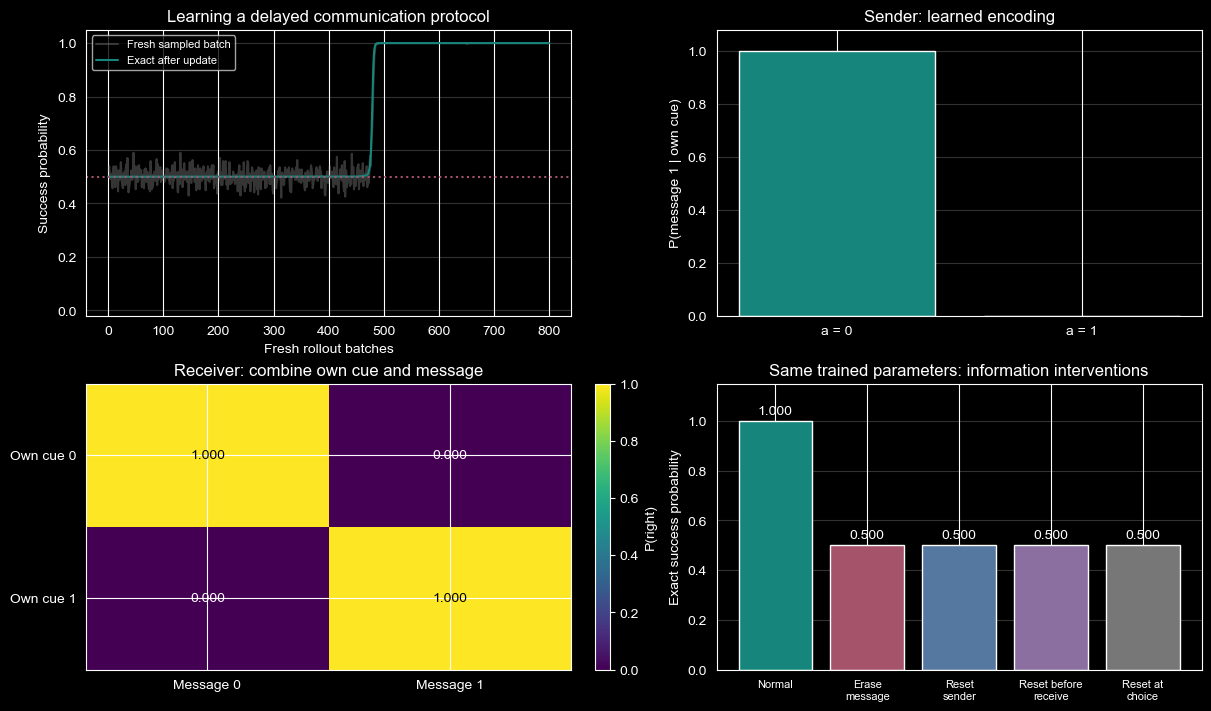

SUMMARY_JSON={"seed": 7, "pytorch": "2.10.0+cu128", "device": "cpu", "training_episodes": 204800, "environment_steps": 819200, "all_agent_actions_including_wait": 1638400, "free_policy_decisions": 409600, "optimizer_steps": 800, "initial_exact_success": 0.4999995827674866, "final_exact_success": 0.999988317489624, "sender_message1": [0.9999988079071045, 1.5113065501282108e-06], "receiver_right": [[0.999992847442627, 1.5030853319331072e-05], [5.600695203611394e-06, 0.9999865293502808]], "interventions": {"normal": 0.999988317489624, "erase_message": 0.5, "reset_sender": 0.4999999701976776, "reset_receiver_before_message": 0.5, "reset_receiver_at_choice": 0.4999999701976776}, "sampled_successes": 1000, "sampled_episodes": 1000, "greedy_successes": 4, "checks_passed": 40, "checks": ["four real transitions per episode", "collection keeps parameters fixed", "complete episode time agent feature axes", "rollout tensors carry no computation graph", "waiting transitions have zero reward", "only

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
updates = [row["update"] for row in history]
axes[0, 0].plot(updates, [row["sample_success_before"] for row in history],
                color="#999999", alpha=0.35, label="Fresh sampled batch")
axes[0, 0].plot([0] + updates, [initial_stats["exact_success"]] +
                [row["exact_success_after"] for row in history], color="#16867c", label="Exact after update")
axes[0, 0].axhline(0.5, linestyle=":", color="#a5536a")
axes[0, 0].set(title="Learning a delayed communication protocol", xlabel="Fresh rollout batches",
               ylabel="Success probability", ylim=(-0.02, 1.05))
axes[0, 0].legend(fontsize=8)
axes[0, 1].bar(["a = 0", "a = 1"], final_stats["sender_message1"], color=["#16867c", "#a5536a"])
axes[0, 1].set(title="Sender: learned encoding", ylabel="P(message 1 | own cue)", ylim=(0, 1.08))
image = axes[1, 0].imshow(final_stats["receiver_right"], vmin=0, vmax=1, cmap="viridis", aspect="auto")
axes[1, 0].set(title="Receiver: combine own cue and message", xticks=[0, 1],
               xticklabels=["Message 0", "Message 1"], yticks=[0, 1], yticklabels=["Own cue 0", "Own cue 1"])
for b, m in itertools.product((0, 1), repeat=2):
    value = final_stats["receiver_right"][b][m]
    axes[1, 0].text(m, b, f"{value:.3f}", ha="center", va="center",
                     color="white" if value < 0.5 else "black")
fig.colorbar(image, ax=axes[1, 0], label="P(right)")
labels = ["Normal", "Erase\nmessage", "Reset\nsender", "Reset before\nreceive", "Reset at\nchoice"]
bars = axes[1, 1].bar(labels, list(interventions.values()),
                      color=["#16867c", "#a5536a", "#5578a0", "#8a6fa0", "#777777"])
axes[1, 1].bar_label(bars, fmt="%.3f", padding=3)
axes[1, 1].set(title="Same trained parameters: information interventions",
               ylabel="Exact success probability", ylim=(0, 1.15))
axes[1, 1].tick_params(axis="x", labelsize=8)
for ax in (axes[0, 0], axes[0, 1], axes[1, 1]):
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
plt.show()

summary = {
    "seed": seed, "pytorch": torch.__version__, "device": "cpu",
    "training_episodes": episodes_per_batch * num_updates,
    "environment_steps": episodes_per_batch * num_updates * horizon,
    "all_agent_actions_including_wait": episodes_per_batch * num_updates * horizon * 2,
    "free_policy_decisions": episodes_per_batch * num_updates * 2,
    "optimizer_steps": num_updates,
    "initial_exact_success": initial_stats["exact_success"],
    "final_exact_success": final_stats["exact_success"],
    "sender_message1": final_stats["sender_message1"],
    "receiver_right": final_stats["receiver_right"],
    "interventions": interventions,
    "sampled_successes": sampled_successes, "sampled_episodes": eval_episodes,
    "greedy_successes": int(greedy_batch["rewards"][:, -1].sum().item()),
    "checks_passed": len(checks), "checks": checks,
    "symmetric_expected_gradient_l1": [g.abs().sum().item() for g in symmetric_gradients],
    "weak_exact_success": weak_success.item(),
    "complete_trace_cues_1_0": [{
        "t": t, "obs": greedy_batch["obs"][2, t].tolist(),
        "actions": greedy_batch["actions"][2, t].tolist(),
        "reward": greedy_batch["rewards"][2, t].item(),
        "terminated": greedy_batch["terminated"][2, t].item(),
    } for t in range(horizon)],
}
print("SUMMARY_JSON=" + json.dumps(summary, ensure_ascii=True))

## 12. 阅读边界与参考

这是教师提供的分段练习，不等于学习者已独立写出或掌握。
同一组训练参数下的消息/记忆干预说明当前策略利用了这些信息；
没有比较不同算法，也没有多种子性能结论。
普通离散消息经自己的 log_prob 学习，没有把接收者梯度穿过整数。
反事实优势的前文算例没有在这里悄悄替换团队评分。
本练习不含 Q Critic、PPO、COMA、RIAL/DIAL 复现、丢包或跨队友泛化。

参考：

- [PyTorch 2.11：Score function / REINFORCE](https://docs.pytorch.org/docs/2.11/distributions.html#score-function)
- [PyTorch 2.11：GRU 输入、输出和隐藏状态](https://docs.pytorch.org/docs/2.11/generated/torch.nn.GRU.html)
- [Spinning Up：baseline 与策略梯度](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)
- [Foerster 等：Learning to Communicate with Deep Multi-Agent Reinforcement Learning](https://arxiv.org/abs/1605.06676)